In [5]:
import jax
import jax.numpy as jnp
from jax import random, grad, jit, vmap
import optax

# MLP and MG_NN classes as provided by the user
class MLP:
    """Simple MLP for approximating functions without Flax, adapted for variable input dimensions."""
    def __init__(self, input_dim, hidden_dims=(64, 64), activation=jnp.tanh, lb=None, ub=None, normalize_input=True, seed=0):
        self.input_dim = input_dim
        self.hidden_dims = hidden_dims
        self.activation = activation
        self.normalize_input = normalize_input
        if normalize_input:
            self.lb = lb if lb is not None else jnp.zeros((input_dim,))
            self.ub = ub if ub is not None else jnp.ones((input_dim,))
        self.key = random.PRNGKey(seed)
        self.params = self.initialize_params()

    def initialize_params(self):
        params = []
        num_layers = len(self.hidden_dims) + 1
        keys = random.split(self.key, num_layers)
        a = jnp.sqrt(0.01)
        params.append(a)
        layers = [self.input_dim] + list(self.hidden_dims) + [1]
        for l in range(num_layers):
            W = self.xavier_init((layers[l], layers[l+1]), keys[l])
            b = jnp.zeros((layers[l+1],), dtype=jnp.float32)
            params.append((W, b))
        return params

    def xavier_init(self, size, key):
        in_dim, out_dim = size
        xavier_stddev = jnp.sqrt(2 / (in_dim + out_dim))
        return random.truncated_normal(key, -2, 2, shape=(out_dim, in_dim), dtype=jnp.float32) * xavier_stddev

    def forward(self, params, x, extra_output=False):
        if self.normalize_input:
            x = 2.0 * (x - self.lb) / (self.ub - self.lb) - 1.0
        a = params[0]
        for l in range(1, len(params) - 1):
            W, b = params[l]
            x = jnp.dot(x, W.T) + b
            x = self.activation(10.0 * a * x)
        W, b = params[-1]
        y = jnp.dot(x, W.T) + b
        out_wo_layer = x
        out = jnp.squeeze(y)
        if extra_output:
            return out, out_wo_layer
        else:
            return out

    def __call__(self, params, x):
        return self.forward(params, x)

class MG_NN:
    """Multi-Grade Neural Network for regression, stacking shallow MLPs."""
    def __init__(self, input_dim, hidden_dims_list, activation=jnp.tanh, lb=None, ub=None, seed=0):
        self.input_dim = input_dim
        self.hidden_dims_list = hidden_dims_list
        self.activation = activation
        self.lb = lb
        self.ub = ub
        self.seed = seed
        self.mlps = []
        self.current_grade = 0

    def add_grade(self):
        if self.current_grade == 0:
            mlp = MLP(input_dim=self.input_dim,
                      hidden_dims=self.hidden_dims_list[self.current_grade],
                      activation=self.activation,
                      lb=self.lb,
                      ub=self.ub,
                      normalize_input=True,
                      seed=self.seed)
        else:
            last_hidden_dim = self.hidden_dims_list[self.current_grade - 1][-1]
            mlp = MLP(input_dim=last_hidden_dim,
                      hidden_dims=self.hidden_dims_list[self.current_grade],
                      activation=self.activation,
                      normalize_input=False,
                      seed=self.seed)
        self.mlps.append(mlp)
        self.current_grade += 1

    def forward(self, x):
        temp = x
        sum_out = 0
        for mlp in self.mlps:
            out, out_wo_layer = mlp.forward(mlp.params, temp, extra_output=True)
            sum_out += out
            temp = out_wo_layer
        return sum_out


In [6]:
# Define the Burgers equation residual

def burgers_residual(u, X):
    nu = 0.01 / jnp.pi
    u_val = u(X)
    grad_u = grad(u, 0)(X)
    u_x = grad_u[0]
    u_t = grad_u[1]
    u_xx = grad(lambda X: grad(u, 0)(X)[0], 0)(X)[0]
    return u_t + u_val * u_x - nu * u_xx

# Initial condition
def initial_condition(x):
    return -jnp.sin(jnp.pi * x)

# Define the boundary conditions
def boundary_condition(t):
    return 0.0

# Helper function for second stage forward pass
def forward_with_params(mg_nn, params_list, x):
    temp = x
    sum_out = 0
    for i, mlp in enumerate(mg_nn.mlps):
        params = params_list[i]
        out, out_wo_layer = mlp.forward(params, temp, extra_output=True)
        sum_out += out
        temp = out_wo_layer
    return sum_out


# Loss function for the first stage
def loss_fn(params, mlp, X_input, mlp_index, mg_nn):
    def get_total_u(X):
        temp = X
        sum_out = 0
        for i in range(mlp_index-1):
            out, out_wo_layer = mg_nn.mlps[i].forward(mg_nn.mlps[i].params, temp, extra_output=True)
            sum_out += out
            temp = out_wo_layer
        out_current = mlp.forward(params, temp)
        return sum_out + out_current

    total_u = lambda X: get_total_u(X)

    # PDE residual loss
    residual = vmap(burgers_residual, (None, 0))(total_u, X_input)
    loss_pde = jnp.mean(residual**2)

    # Generate IC and BC points (assuming X_input has shape [N, 2])
    N = 200  # Number of points for IC and BC
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    
    # Initial condition loss
    t_ic = jnp.zeros_like(x)
    X_ic = jnp.stack([x, t_ic], axis=1)
    u_ic_pred = vmap(total_u)(X_ic)
    u_ic_true = initial_condition(x)
    loss_ic = jnp.mean((u_ic_pred - u_ic_true)**2)

    # Boundary condition loss
    x_lb = -1.0 * jnp.ones_like(t)
    x_ub = 1.0 * jnp.ones_like(t)
    X_lb = jnp.stack([x_lb, t], axis=1)
    X_ub = jnp.stack([x_ub, t], axis=1)
    u_lb_pred = vmap(total_u)(X_lb)
    u_ub_pred = vmap(total_u)(X_ub)
    loss_bc = jnp.mean(u_lb_pred**2) + jnp.mean(u_ub_pred**2)

    return loss_pde + loss_ic + loss_bc
    # return loss_ic + loss_bc

# Loss function for the second stage
def loss_fn_second_stage(params_last_k, mg_nn, X_input, k):
    n = len(mg_nn.mlps)
    m = n - k + 1
    fixed_params = [mg_nn.mlps[i].params for i in range(m-1)] if m > 1 else []
    params_list = fixed_params + list(params_last_k)

    def total_u(X):
        return forward_with_params(mg_nn, params_list, X)

    residual = vmap(burgers_residual, (None, 0))(total_u, X_input)
    loss_pde = jnp.mean(residual**2)

    N = 200
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    t_ic = jnp.zeros_like(x)
    X_ic = jnp.stack([x, t_ic], axis=1)
    u_ic_pred = vmap(total_u)(X_ic)
    u_ic_true = initial_condition(x)
    loss_ic = jnp.mean((u_ic_pred - u_ic_true)**2)

    x_lb = -1.0 * jnp.ones_like(t)
    x_ub = 1.0 * jnp.ones_like(t)
    X_lb = jnp.stack([x_lb, t], axis=1)
    X_ub = jnp.stack([x_ub, t], axis=1)
    u_lb_pred = vmap(total_u)(X_lb)
    u_ub_pred = vmap(total_u)(X_ub)
    loss_bc = jnp.mean(u_lb_pred**2) + jnp.mean(u_ub_pred**2)

    return loss_pde + loss_ic + loss_bc

In [7]:
# Training function for the first stage
def train_grade(mg_nn, mlp_index, X_input, epochs, lr):
    mlp = mg_nn.mlps[mlp_index-1]
    params = mlp.params
    optimizer = optax.adam(lr)
    opt_state = optimizer.init(params)

    @jit
    def step(params, opt_state):
        grads = grad(loss_fn)(params, mlp, X_input, mlp_index, mg_nn)
        updates, opt_state = optimizer.update(grads, opt_state)
        params = optax.apply_updates(params, updates)
        return params, opt_state

    for epoch in range(epochs):
        mlp.params, opt_state = step(mlp.params, opt_state)
        if epoch % 100 == 0:
            loss = loss_fn(mlp.params, mlp, X_input, mlp_index, mg_nn)
            print(f"Grade {mlp_index}, Epoch {epoch}, Loss: {loss:.6f}")
    return mlp.params

# Main function to solve Burgers equation with MG_NN
def solve_burgers(total_grade=3, k=2, dims_list = [(40, 40), (40, 40), (40, 40)]):
    X_grid = jnp.stack(jnp.meshgrid(jnp.linspace(-1, 1, 100), jnp.linspace(0, 1, 100)), axis=-1).reshape(-1, 2)
    lb = jnp.array([-1.0, 0.0])
    ub = jnp.array([1.0, 1.0])
    hidden_dims_list = dims_list
    activation = jnp.tanh
    seed = 0
    epochs = 5000
    lr = 1e-3

    N = 200
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    X, T = jnp.meshgrid(x, t)
    X_flat = X.flatten()
    T_flat = T.flatten()
    X_input = jnp.stack([X_flat, T_flat], axis=-1)

    mg_nn = MG_NN(input_dim=2, hidden_dims_list=hidden_dims_list, activation=activation, lb=lb, ub=ub, seed=seed)

    # Stage 1: Train each grade sequentially
    for mlp_index in range(1, total_grade+1):
        mg_nn.add_grade()
        print(f"\nTraining Grade {mg_nn.current_grade}")
        train_grade(mg_nn, mlp_index, X_input, epochs, lr)

    # Stage 2: Unfreeze and retrain the last k grades
    if k > 0 and k <= total_grade:
        print(f"\nSecond stage: Unfreezing last {k} grades")
        params_last_k = [mlp.params for mlp in mg_nn.mlps[-k:]]
        optimizer = optax.adam(lr)
        opt_state = optimizer.init(params_last_k)

        @jit
        def step(params_last_k, opt_state):
            grads = grad(loss_fn_second_stage)(params_last_k, mg_nn, X_input, k)
            updates, opt_state = optimizer.update(grads, opt_state)
            params_last_k = optax.apply_updates(params_last_k, updates)
            return params_last_k, opt_state

        for epoch in range(epochs):
            params_last_k, opt_state = step(params_last_k, opt_state)
            if epoch % 100 == 0:
                loss = loss_fn_second_stage(params_last_k, mg_nn, X_input, k)
                print(f"Second stage, Epoch {epoch}, Loss: {loss:.6f}")

        # Update the MLP parameters with the refined values
        for mlp, params in zip(mg_nn.mlps[-k:], params_last_k):
            mlp.params = params

    # Final prediction
    u_pred = mg_nn.forward(X_grid)
    print("\nTraining completed. Final prediction shape:", u_pred.shape)
    return u_pred.reshape(100, 100)


In [8]:
u_pred = solve_burgers(total_grade=4, k=3, dims_list = [(40, 40, 40, 40), (40, 40), (40,40)])


Training Grade 1
Grade 1, Epoch 0, Loss: 0.460077
Grade 1, Epoch 100, Loss: 0.166884
Grade 1, Epoch 200, Loss: 0.140357
Grade 1, Epoch 300, Loss: 0.112194
Grade 1, Epoch 400, Loss: 0.098161
Grade 1, Epoch 500, Loss: 0.091694
Grade 1, Epoch 600, Loss: 0.087729
Grade 1, Epoch 700, Loss: 0.084380
Grade 1, Epoch 800, Loss: 0.082184
Grade 1, Epoch 900, Loss: 0.080312
Grade 1, Epoch 1000, Loss: 0.078474
Grade 1, Epoch 1100, Loss: 0.075053
Grade 1, Epoch 1200, Loss: 0.069060
Grade 1, Epoch 1300, Loss: 0.059564
Grade 1, Epoch 1400, Loss: 0.051562
Grade 1, Epoch 1500, Loss: 0.045187
Grade 1, Epoch 1600, Loss: 0.041096
Grade 1, Epoch 1700, Loss: 0.038419
Grade 1, Epoch 1800, Loss: 0.038923
Grade 1, Epoch 1900, Loss: 0.033552
Grade 1, Epoch 2000, Loss: 0.031281
Grade 1, Epoch 2100, Loss: 0.029715
Grade 1, Epoch 2200, Loss: 0.028235
Grade 1, Epoch 2300, Loss: 0.026839
Grade 1, Epoch 2400, Loss: 0.026604
Grade 1, Epoch 2500, Loss: 0.049558
Grade 1, Epoch 2600, Loss: 0.022296
Grade 1, Epoch 2700, L

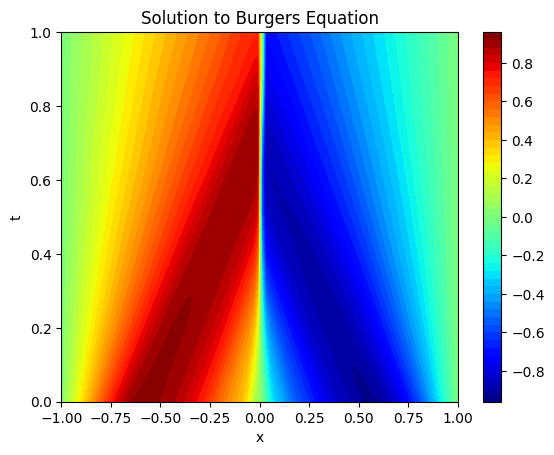

In [10]:
import matplotlib.pyplot as plt
import numpy as np

def plot_solution(u):
    """
    Plots the solution to the Burgers equation using a contour plot.

    Args:
        u_pred (jax.numpy.ndarray or numpy.ndarray): 2D array of shape (100, 100) representing the solution.
    """
    # Generate spatial and temporal grids
    x = np.linspace(-1, 1, 100)
    t = np.linspace(0, 1, 100)
    X, T = np.meshgrid(x, t)
    
    # Plot the contour
    plt.contourf(X, T, u, levels=50, cmap='jet')
    plt.colorbar()
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Solution to Burgers Equation')
    plt.show()
plot_solution(u_pred)

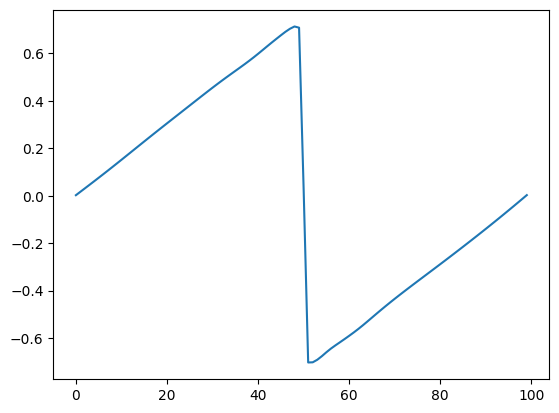

In [11]:
plt.plot(u_pred[-1,:])

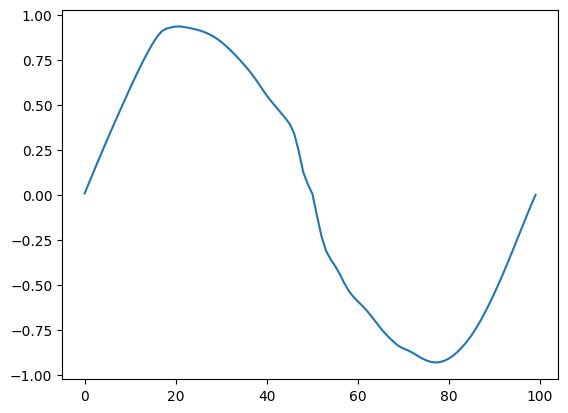

In [12]:
plt.plot(u_pred[0,:])

In [ ]:
def loss_fn(params, mlp, x, t, mlp_index, prev_outputs=None):
    if mlp_index == 0:
        u_pred = lambda x, t: mlp(params, jnp.stack([x, t], axis=-1))
    else:
        u_pred = lambda x, t: mlp(params, x)  # Input is hidden activations

    # Total prediction includes previous grades if any
    total_u = lambda x, t: u_pred(x, t) + (prev_outputs(x, t) if prev_outputs else 0.0)

    # PDE residual loss
    residual = vmap(burgers_residual, (None, 0, 0))(total_u, x, t)
    loss_pde = jnp.mean(residual**2)

    # Initial condition loss
    t_ic = jnp.zeros_like(x)
    u_ic_pred = vmap(total_u, (0, 0))(x, t_ic)
    u_ic_true = initial_condition(x)
    loss_ic = jnp.mean((u_ic_pred - u_ic_true)**2)

    # Boundary condition loss
    x_lb = -1.0 * jnp.ones_like(t)
    x_ub = 1.0 * jnp.ones_like(t)
    u_lb_pred = vmap(total_u, (0, 0))(x_lb, t)
    u_ub_pred = vmap(total_u, (0, 0))(x_ub, t)
    loss_bc = jnp.mean(u_lb_pred**2) + jnp.mean(u_ub_pred**2)

    return loss_pde + loss_ic + loss_bc

In [ ]:
# Define the loss function for a single grade
def loss_fn(params, mlp, X_input, mlp_index, prev_outputs=None):
    u_pred = lambda X_input: mlp(params, X_input)  # Input is hidden activations

    # Total prediction includes previous grades if any
    total_u = lambda X_input: u_pred(X_input) + (prev_outputs(X_input) if prev_outputs else 0.0)

    # PDE residual loss
    residual = vmap(burgers_residual, (None, 0))(total_u, X_input)
    loss_pde = jnp.mean(residual**2)

    # Initial condition loss
    t_ic = jnp.zeros_like(x)
    u_ic_pred = vmap(total_u, (0, 0))(x, t_ic)
    u_ic_true = initial_condition(x)
    loss_ic = jnp.mean((u_ic_pred - u_ic_true)**2)

    # Boundary condition loss
    x_lb = -1.0 * jnp.ones_like(t)
    x_ub = 1.0 * jnp.ones_like(t)
    u_lb_pred = vmap(total_u, (0, 0))(x_lb, t)
    u_ub_pred = vmap(total_u, (0, 0))(x_ub, t)
    loss_bc = jnp.mean(u_lb_pred**2) + jnp.mean(u_ub_pred**2)

    return loss_pde + loss_ic + loss_bc

In [ ]:
# Modified loss function
def loss_fn(params, mlp, X_input, mlp_index, mg_nn):
    def get_total_u(X):
        if mlp_index == 0:
            return mlp.forward(params, X)
        else:
            temp = X
            sum_out = 0
            for i in range(mlp_index):
                out, out_wo_layer = mg_nn.mlps[i].forward(mg_nn.mlps[i].params, temp, extra_output=True)
                sum_out += out
                temp = out_wo_layer
            out_current = mlp.forward(params, temp)
            return sum_out + out_current

    total_u = lambda X: get_total_u(X)

    # PDE residual loss
    residual = vmap(burgers_residual, (None, 0))(total_u, X_input)
    loss_pde = jnp.mean(residual**2)

    # Generate IC and BC points (assuming X_input has shape [N, 2])
    N = 100  # Number of points for IC and BC
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    
    # Initial condition loss
    t_ic = jnp.zeros_like(x)
    X_ic = jnp.stack([x, t_ic], axis=1)
    u_ic_pred = vmap(total_u)(X_ic)
    u_ic_true = initial_condition(x)
    loss_ic = jnp.mean((u_ic_pred - u_ic_true)**2)

    # Boundary condition loss
    x_lb = -1.0 * jnp.ones_like(t)
    x_ub = 1.0 * jnp.ones_like(t)
    X_lb = jnp.stack([x_lb, t], axis=1)
    X_ub = jnp.stack([x_ub, t], axis=1)
    u_lb_pred = vmap(total_u)(X_lb)
    u_ub_pred = vmap(total_u)(X_ub)
    loss_bc = jnp.mean(u_lb_pred**2) + jnp.mean(u_ub_pred**2)

    return loss_pde + loss_ic + loss_bc